<a href="https://colab.research.google.com/github/benameur21/Brain-Tumor-Segmentation-UNet-TL/blob/main/Brain_tumor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/benameur21/Brain-Tumor-Segmentation-UNet-TL.git

Cloning into 'Brain-Tumor-Segmentation-UNet-TL'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 12 (delta 1), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 1.07 MiB | 9.73 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [2]:
%cd Brain-Tumor-Segmentation-UNet-TL.git
!git status

[Errno 2] No such file or directory: 'Brain-Tumor-Segmentation-UNet-TL.git'
/content
fatal: not a git repository (or any of the parent directories): .git


# Part A

**A0.Environment Setup**

Install Required Libraries

In [3]:
!pip install -q segmentation-models-pytorch==0.3.4
!pip install -q albumentations
!pip install -q opencv-python matplotlib pandas scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Import Libraries

In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

Set Random Seed

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


Detect Computing Device

In [6]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU: Tesla T4


Q01 : The chosen hardware is the GPU (using CUDA) specifically an NVIDIA Tesla T4 it enhances the speed of simultaneous calculations leading to a decrease in training duration when set against the CPU

**A1.LGG MRI Dataset Exploration**

1.Dataset Inventory

*Define Dataset Path and List Files*

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Path to dataset files: /kaggle/input/lgg-mri-segmentation


In [8]:
import os
import glob

DATASET_DIR = "/kaggle/input/lgg-mri-segmentation"

all_files = glob.glob(
    os.path.join(DATASET_DIR, "**", "*.tif"),
    recursive=True
)

print("Dataset directory:", DATASET_DIR)
print("Total TIFF files:", len(all_files))
print("First 5 files:", all_files[:5])

Dataset directory: /kaggle/input/lgg-mri-segmentation
Total TIFF files: 15716
First 5 files: ['/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_45.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_56_mask.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_57.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_33.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_27.tif']


*Separate Images and Masks*

In [9]:
mask_paths = [
    path for path in all_files
    if path.endswith("_mask.tif")
]

mri_paths = [
    path for path in all_files
    if not path.endswith("_mask.tif")
]

print("MRI images:", len(mri_paths))
print("Segmentation masks:", len(mask_paths))

MRI images: 7858
Segmentation masks: 7858


*Match Images and Masks*

In [10]:
from pathlib import Path

mask_dict = {
    Path(path).stem.replace("_mask", ""): path
    for path in mask_paths
}

image_mask_pairs = []

for image_path in mri_paths:
    image_name = Path(image_path).stem

    if image_name in mask_dict:
        image_mask_pairs.append(
            (image_path, mask_dict[image_name])
        )

print("Matched image-mask pairs:", len(image_mask_pairs))

Matched image-mask pairs: 7858


*Count Patients*

In [11]:
patient_ids = {
    "_".join(Path(image_path).stem.split("_")[:3])
    for image_path, mask_path in image_mask_pairs
}

print("Number of patients:", len(patient_ids))
print("First 10 patient IDs:", sorted(patient_ids)[:10])

Number of patients: 110
First 10 patient IDs: ['TCGA_CS_4941', 'TCGA_CS_4942', 'TCGA_CS_4943', 'TCGA_CS_4944', 'TCGA_CS_5393', 'TCGA_CS_5395', 'TCGA_CS_5396', 'TCGA_CS_5397', 'TCGA_CS_6186', 'TCGA_CS_6188']


2.Visualize MRI Images and Masks

*Display Sample Images*

In [12]:
import cv2
import matplotlib.pyplot as plt

def display_samples(pairs, n=3):
    fig, axes = plt.subplots(n, 2, figsize=(10, 4 * n))

    for i, (image_path, mask_path) in enumerate(pairs[:n]):
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        axes[i, 0].imshow(image)
        axes[i, 0].set_title("MRI Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Segmentation Mask")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

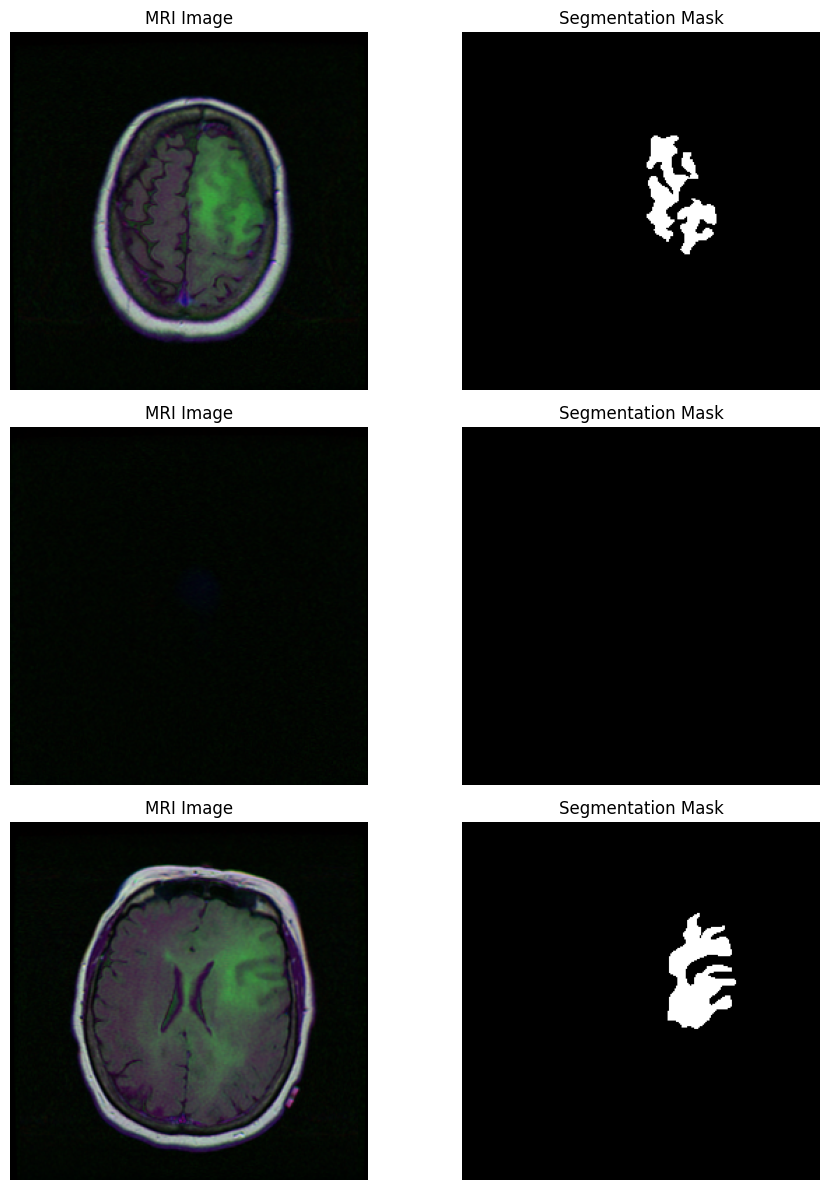

In [13]:
display_samples(image_mask_pairs, n=3)

*Display Samples With and Without Anomalies*

Samples with anomalies: 2746
Samples without anomalies: 5112

Samples with anomalies:


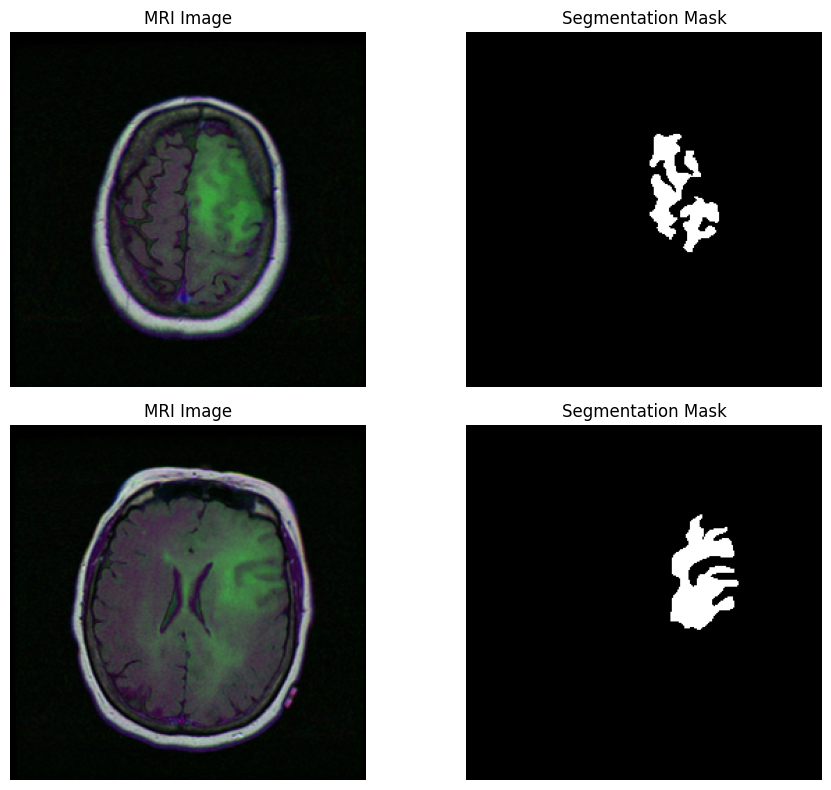


Samples without anomalies:


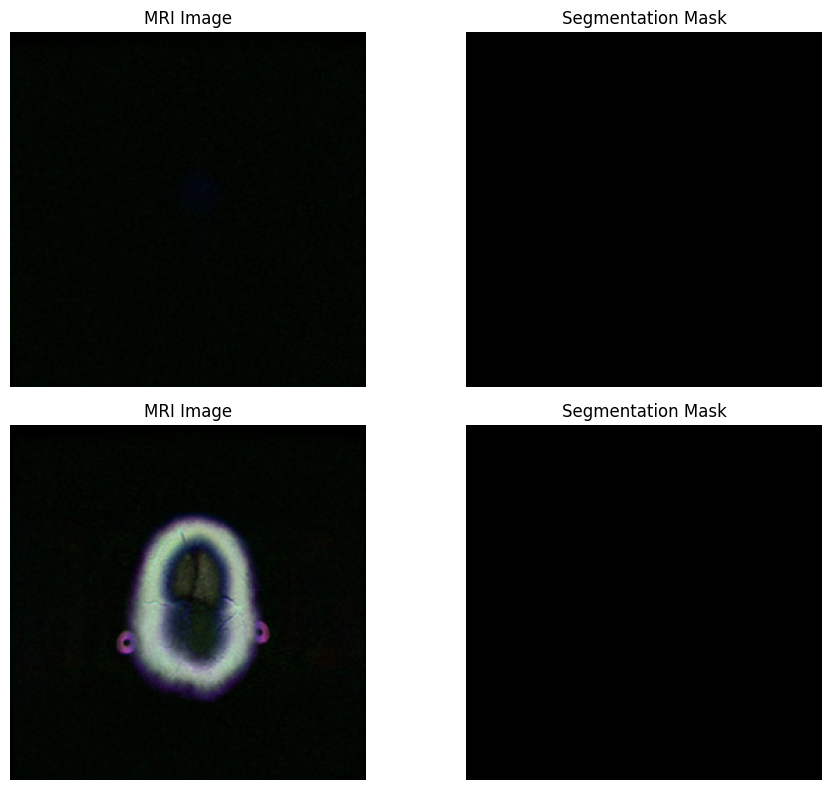

In [14]:
positive_samples = []
negative_samples = []

for image_path, mask_path in image_mask_pairs:
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if np.any(mask > 0):
        positive_samples.append((image_path, mask_path))
    else:
        negative_samples.append((image_path, mask_path))

print("Samples with anomalies:", len(positive_samples))
print("Samples without anomalies:", len(negative_samples))

print("\nSamples with anomalies:")
display_samples(positive_samples, n=2)

print("\nSamples without anomalies:")
display_samples(negative_samples, n=2)

3.Analyze Mask Values and Empty Masks

*Inspect Mask Pixel Values*

In [15]:
sample_mask = cv2.imread(
    image_mask_pairs[0][1],
    cv2.IMREAD_GRAYSCALE
)

unique_values = np.unique(sample_mask)

print("Unique mask values:", unique_values)
print("Mask shape:", sample_mask.shape)

Unique mask values: [  0 255]
Mask shape: (256, 256)


*Calculate Empty Mask Statistics*

In [16]:
total_masks = len(image_mask_pairs)
empty_masks = len(negative_samples)
non_empty_masks = len(positive_samples)

empty_percentage = (empty_masks / total_masks) * 100

print("Total masks:", total_masks)
print("Empty masks:", empty_masks)
print("Non-empty masks:", non_empty_masks)
print(f"Empty mask percentage: {empty_percentage:.2f}%")

Total masks: 7858
Empty masks: 5112
Non-empty masks: 2746
Empty mask percentage: 65.05%


Q02:The dataset includes 7,858 pairs of MRI images and masks linked to 110 individuals.These masks serve as segmentation labels rather than being colored images and they comprise two distinct values: 0 indicating the background and 255 denoting the highlighted tumor area

Q03:A mask that is entirely black signifies that there is no marked tumor area in the related MRI slice, as seen in the second output shown by 'display_samples(image_mask_pairs, n=3)' where both the MRI image and the segmentation mask are nearly completely dark except for some details plus this step is essential to keep these instances during both training and evaluation stages as they assist the model in identifying slices that lack labeled tumors which ultimately helps decrease false-positive outcomes
In this dataset 5,112 masks are empty representing 65.05% of the total


**A2.Data Preparation and Data Leakage Prevention**

1.Patient-Level Data Splitting

*Prepare Patient IDs*

In [17]:
import random
import numpy as np
from sklearn.model_selection import train_test_split

patient_ids = sorted(list(patient_ids))

print("Total patients:", len(patient_ids))

Total patients: 110


*Split Patients*

In [18]:
RANDOM_SEED = 42

train_patients, temp_patients = train_test_split(
    patient_ids,
    test_size=0.30,
    random_state=RANDOM_SEED
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=RANDOM_SEED
)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

Training patients: 77
Validation patients: 16
Test patients: 17
